# NFL Moneyball: efficiency, the betting market and value per dollar

## Problem
Two Moneyball questions: (1) does a model built on public efficiency data (EPA per play) predict game margins better than the betting market? (2) which skill players delivered the most value over replacement per dollar of salary?

## Data
nflverse public releases: team-week stats (EPA), `games.csv` with closing spreads (2015 to 2026), player-week stats, and historical contracts (OverTheCap data republished by nflverse; signings through 2022 only, so the salary analysis uses the 2022 season). ESPN has no public NFL salary page (404) and no JDK is installed here, so a Java scraper was not an option.

## Method
- Features: exponentially weighted offensive EPA/play and defensive EPA/play allowed, matchup terms, rest difference, all shifted so only pre-game data is used.
- Model: `RidgeCV` fitted on prior seasons, evaluated by MAE and against-the-spread (ATS) hit rate against the closing line.
- Player value: $\text{VORP}_i=\text{EPA}_i - r_{pos}\cdot \text{touches}_i$, where $r_{pos}$ is EPA per touch of the first player outside the starter pool of that position.
- Salary: average per year (APY) of the contract in force, joined by name and position.

 season  games  model_mae  market_mae  blend_mae  model_ats
   2023    272     10.721       9.901     10.201      0.446
   2024    272     10.086       9.610      9.734      0.526
   2025    272     10.229       9.722      9.831      0.487
   2026    150      9.856       9.567      9.649      0.521

Mean MAE: model 10.22 | market 9.70 | blend 9.85


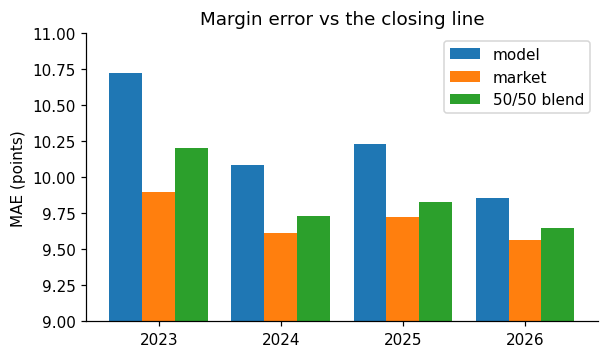

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import moneyball as M
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
bt = M.margin_model(2015, 2026)
print(bt.round(3).to_string(index=False))
print(f"\nMean MAE: model {bt.model_mae.mean():.2f} | market {bt.market_mae.mean():.2f} | blend {bt.blend_mae.mean():.2f}")
fig, ax = plt.subplots(figsize=(6,3.4)); x=np.arange(len(bt)); w=.27
ax.bar(x-w, bt.model_mae, w, label='model'); ax.bar(x, bt.market_mae, w, label='market'); ax.bar(x+w, bt.blend_mae, w, label='50/50 blend')
ax.set_xticks(x); ax.set_xticklabels(bt.season); ax.set_ylim(9, 11); ax.set_ylabel('MAE (points)'); ax.legend(); ax.set_title('Margin error vs the closing line'); plt.show()

In [2]:
# Is the model's disagreement with the market informative? Pool seasons >= 2022 and bin by |model - market|
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error
g = M.load('https://raw.githubusercontent.com/nflverse/nfldata/master/data/games.csv','games.csv')
g = g[(g.game_type=='REG') & g.season.between(2015, 2026)].dropna(subset=['result','spread_line'])
r = M.add_rolling(M.team_weeks(2015, 2026))
h = r.add_prefix('h_').rename(columns={'h_season':'season','h_week':'week','h_team':'home_team'})
a = r.add_prefix('a_').rename(columns={'a_season':'season','a_week':'week','a_team':'away_team'})
d = g.merge(h, on=['season','week','home_team']).merge(a, on=['season','week','away_team']).dropna(subset=['h_off','h_dfn','a_off','a_dfn'])
d['x_off'], d['x_def'] = d.h_off-d.a_dfn, d.a_off-d.h_dfn
X = d[['h_off','h_dfn','a_off','a_dfn','x_off','x_def']].assign(rest=d.home_rest-d.away_rest)
out=[]
for s in range(2022, 2027):
    tr, te = d.season<s, d.season==s
    if not te.any(): continue
    m = RidgeCV(alphas=np.logspace(-2,3,12)).fit(X[tr], d.result[tr])
    out.append(d[te].assign(pred=m.predict(X[te])))
o = pd.concat(out); o['gap'] = o.pred - o.spread_line
o['bucket'] = pd.qcut(o.gap.abs(), 4, labels=['smallest','2','3','largest'])
res = o[o.result != o.spread_line].groupby('bucket', observed=True).apply(lambda t: pd.Series({'games': len(t), 'ATS hit rate': ((t.gap>0)==(t.result>t.spread_line)).mean()}))
print(res.round(3)); print('Overall ATS hit rate', round(((o.gap>0)==(o.result>o.spread_line))[o.result!=o.spread_line].mean(),3))
print('Break-even vs -110 odds is about 0.524')

          games  ATS hit rate
bucket                       
smallest  300.0         0.473
2         303.0         0.528
3         297.0         0.505
largest   302.0         0.510
Overall ATS hit rate 0.504
Break-even vs -110 odds is about 0.524


Top value over replacement, 2022
player_display_name position team   epa  touches  vorp
    Patrick Mahomes       QB   KC 217.8      710 226.2
         Josh Allen       QB  BUF 142.1      691 150.3
        Jalen Hurts       QB  PHI 121.0      625 128.4
         Joe Burrow       QB  CIN  91.9      681 100.0
         Jared Goff       QB  DET  85.9      617  93.2
     Tua Tagovailoa       QB  MIA  87.3      424  92.3
    Trevor Lawrence       QB  JAX  78.6      646  86.2
    Jimmy Garoppolo       QB   SF  72.4      331  76.3
       Daniel Jones       QB  NYG  60.4      592  67.4
      Jaylen Waddle       WR  MIA  77.9      120  60.9
       Travis Kelce       TE   KC  66.5      154  57.6
      Lamar Jackson       QB  BAL  50.3      438  55.4
   Justin Jefferson       WR  MIN  80.7      190  53.8
       Dak Prescott       QB  DAL  47.6      439  52.8
       Stefon Diggs       WR  BUF  73.8      155  51.8


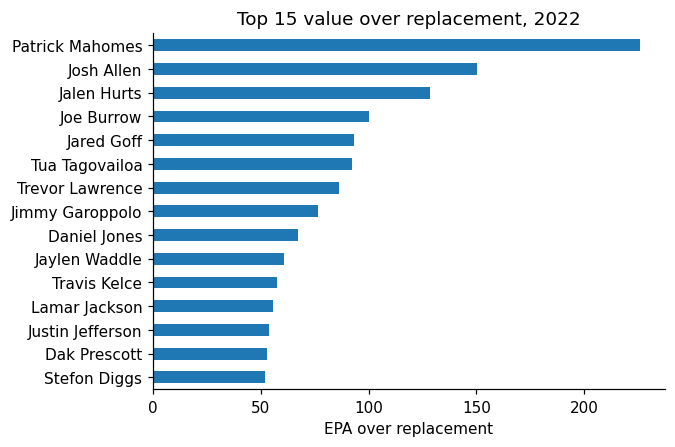

In [3]:
yr = 2022
v = M.value_over_replacement(yr, top=15)
print(f'Top value over replacement, {yr}'); print(v.round(1).to_string(index=False))
v.sort_values('vorp').plot.barh(x='player_display_name', y='vorp', legend=False, figsize=(6,4.2)); plt.xlabel('EPA over replacement'); plt.ylabel(''); plt.title(f'Top 15 value over replacement, {yr}'); plt.show()

126 players with both a 2022 contract and >=100 touches
Correlation of salary (APY) with value over replacement: 0.34


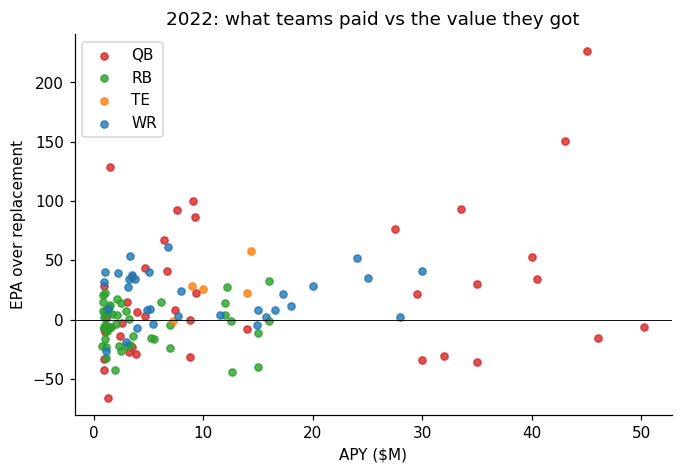

In [4]:
d22 = M.value_vs_salary(2022)
print(len(d22), 'players with both a 2022 contract and >=100 touches')
print('Correlation of salary (APY) with value over replacement:', round(d22[['apy_m','vorp']].corr().iloc[0,1],2))
colors = {'QB':'tab:red','RB':'tab:green','WR':'tab:blue','TE':'tab:orange'}
fig, ax = plt.subplots(figsize=(7,4.5))
for p, t in d22.groupby('position'): ax.scatter(t.apy_m, t.vorp, s=22, label=p, c=colors[p], alpha=.8)
ax.set_xlabel('APY ($M)'); ax.set_ylabel('EPA over replacement'); ax.axhline(0, c='k', lw=.6); ax.legend(); ax.set_title('2022: what teams paid vs the value they got'); plt.show()

In [5]:
cols = ['player_display_name','position','team','vorp','apy_m','draft_round']
print('Best value per $ (cheap and productive)'); print(d22.sort_values('vorp_per_m', ascending=False).head(8)[cols].round(1).to_string(index=False))
big = d22[d22.apy_m >= 10]
print('\nPaid >= $10M/yr, lowest value over replacement'); print(big.sort_values('vorp').head(8)[cols].round(1).to_string(index=False))

Best value per $ (cheap and productive)
player_display_name position team  vorp  apy_m  draft_round
        Jalen Hurts       QB  PHI 128.4    1.5          2.0
  Amon-Ra St. Brown       WR  DET  40.1    1.1          4.0
     Terry McLaurin       WR  WAS  31.9    1.0          3.0
        Brock Purdy       QB   SF  28.3    0.9          7.0
      Jaylen Warren       RB  PIT  20.7    0.9          NaN
     Tyler Allgeier       RB  ATL  22.0    1.0          5.0
       Tony Pollard       RB  DAL  14.6    0.8          4.0
        Tee Higgins       WR  CIN  39.1    2.2          2.0

Paid >= $10M/yr, lowest value over replacement
player_display_name position team  vorp  apy_m  draft_round
        Dalvin Cook       RB  MIN -44.0   12.6          2.0
       Alvin Kamara       RB   NO -39.8   15.0          3.0
     Russell Wilson       QB  DEN -35.7   35.0          3.0
          Matt Ryan       QB  IND -33.8   30.0          1.0
       Carson Wentz       QB  WAS -30.3   32.0          1.0
     Deshaun

In [6]:
d22['rookie_deal'] = d22.apy_m < 4
print(d22.groupby(['position','rookie_deal']).agg(n=('vorp','size'), mean_vorp=('vorp','mean'), mean_apy=('apy_m','mean')).round(1))
vet = d22[~d22.rookie_deal]
print('\nCorrelation salary-VORP, veterans (APY >= $4M):', round(vet[['apy_m','vorp']].corr().iloc[0,1],2))

                       n  mean_vorp  mean_apy
position rookie_deal                         
QB       False        25       39.5      23.4
         True         17       -2.8       2.1
RB       False        14       -4.6      11.0
         True         34       -4.1       1.6
TE       False         5       26.6      10.9
WR       False        19       18.5      14.7
         True         12       21.2       2.5

Correlation salary-VORP, veterans (APY >= $4M): 0.26


## Results
See the outputs above: season-wise MAE of model, market and blend; the ATS hit rate by size of disagreement with the line; the top players by value over replacement; and the relationship between salary and value in 2022.

## Conclusions
1. **The public-data model does not beat the market.** Its MAE is 10.22 points against 9.70 for the closing line, and a 50/50 blend (9.85) is still worse than the line alone. Its against-the-spread hit rate is 50.4%, below the roughly 52.4% needed to break even at standard -110 odds. Even the games where the model disagrees most with the line are only 51.0% winners, so large disagreements are not more reliable. The market already prices EPA-based information.
2. **Salary is only weakly tied to production.** In 2022 the correlation between a contract's APY and EPA over replacement is 0.34 (0.26 among veterans paid at least $4M/yr). Quarterbacks on veteran deals averaged 39.5 EPA over replacement at $23.4M/yr, while quarterbacks on rookie deals averaged -2.8 at $2.1M/yr, so the rookie group's average is pulled down by the many who did not play well, yet it also contains the best bargains.
3. **Where the Moneyball value was in 2022.** The cheapest productive players were mostly rookie-scale: Jalen Hurts ($1.5M APY, 128 EPA over replacement), Amon-Ra St. Brown, Terry McLaurin, Brock Purdy and Tyler Allgeier. At the other end, running backs on large veteran contracts were the worst use of cap (veteran RBs averaged -4.6 at $11.0M/yr), as were veteran quarterbacks such as Russell Wilson, Matt Ryan and Carson Wentz, who produced below replacement while being paid $30M to $35M.
4. **Limits.** The contract data only covers signings through 2022, so the salary analysis is a single-season study and cannot value the current (2026) roster. EPA ignores offensive-line and scheme effects (running backs are punished by it in particular), player names are matched between sources so some players are lost (126 matched), part-season players such as Brock Purdy and Deshaun Watson are judged on few games, and rookie-scale salaries are set by draft slot rather than by market forces.

**Takeaway for the interview:** the Moneyball edge is not in predicting scores better than the market; it is in finding roles where price and production diverge: cheap rookie-scale quarterbacks and receivers, and overpaid veteran running backs. Refreshing the contract data is the first step to apply this to today's rosters.